# Phần Hải (2/2) — Phân Tích Lỗi (Error Analysis) trên Tập Test

Sau khi so sánh 4 mô hình, mô hình có F1-score và Recall cao nhất là **Decision Tree Luồng A**
(Recall $0.7914$, $F_1 = 0.6258$), và mô hình K-NN tốt nhất là **K-NN Luồng A** ($F_1 = 0.5992$).

Notebook này tiến hành mổ xẻ các ca dự đoán sai của mô hình trên tập Test chung (1.409 khách hàng)
để tìm ra nguyên nhân kinh doanh và kỹ thuật đằng sau các nhầm lẫn này.

In [1]:
import sys
from pathlib import Path

# Tự động tìm thư mục gốc của dự án và thêm vào sys.path để import được module src
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").exists():
  PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
  sys.path.insert(0, str(PROJECT_ROOT))

# Các thư viện chuẩn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Import hàm phân tích lỗi từ src/
from src.error_analysis import phan_tich_loi, ve_bieu_do_loi


## 1. Trích xuất nhóm dự đoán trên tập Test (Decision Tree Luồng A)

Phân bố 4 nhóm dự đoán:
Prediction_Type
TN (Đoán đúng Ở lại)     759
TP (Đoán đúng Churn)     296
FP (Nhầm thành Churn)    276
FN (Bỏ sót Churn)         78
Name: count, dtype: int64


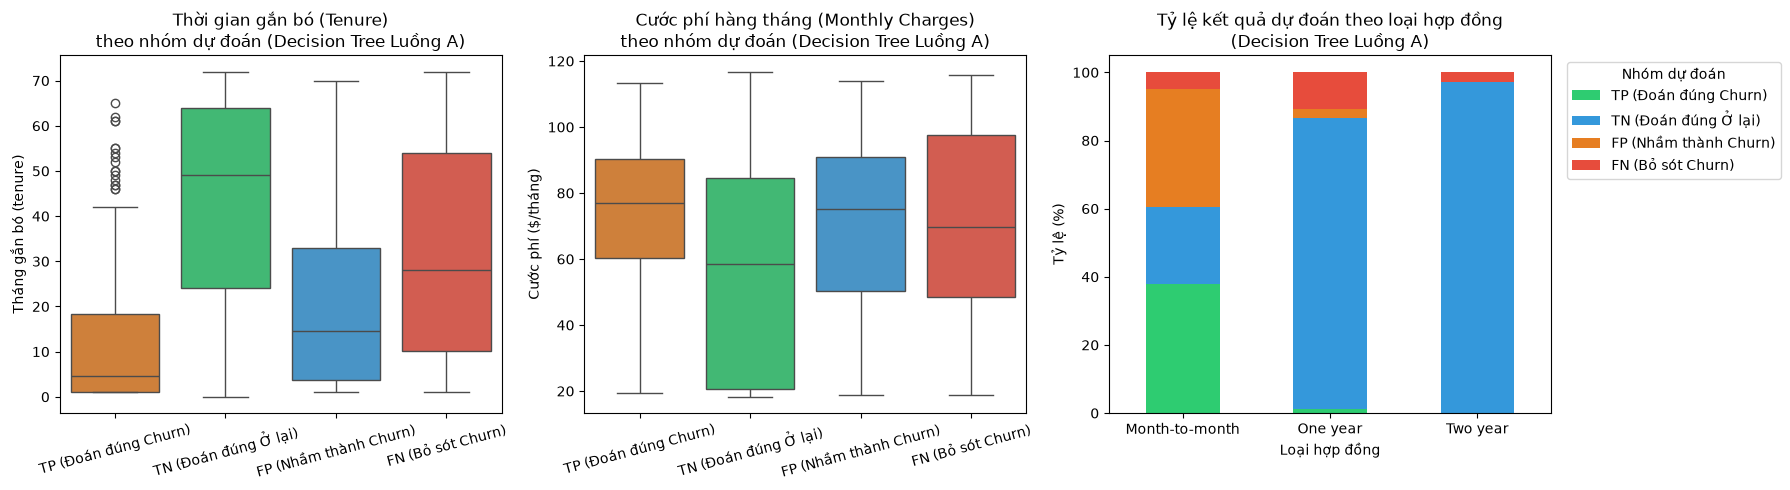

In [2]:
df_dt = phan_tich_loi('decision_tree', luong='A')
print('Phân bố 4 nhóm dự đoán:')
print(df_dt['Prediction_Type'].value_counts())

fig = ve_bieu_do_loi(df_dt, 'Decision Tree Luồng A')
plt.show()


## 2. So sánh với phân tích lỗi của K-NN Luồng A

Phân bố 4 nhóm dự đoán của K-NN:
Prediction_Type
TN (Đoán đúng Ở lại)     883
TP (Đoán đúng Churn)     225
FP (Nhầm thành Churn)    152
FN (Bỏ sót Churn)        149
Name: count, dtype: int64


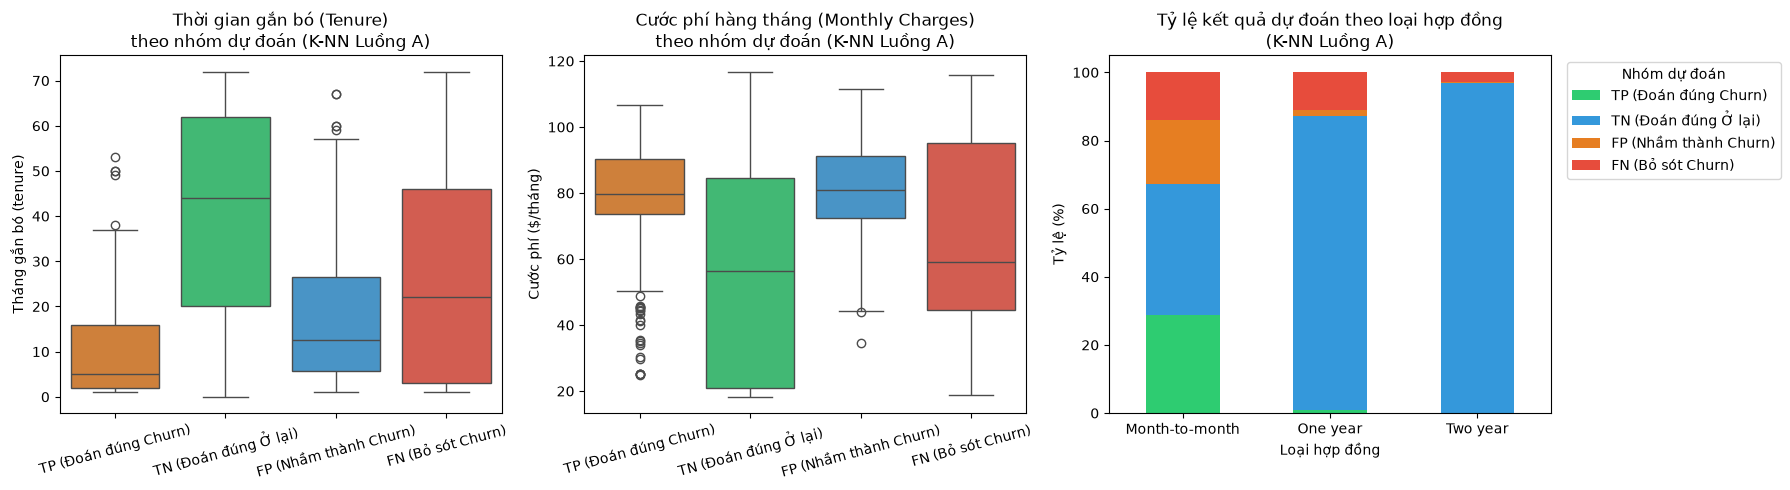

In [3]:
df_knn = phan_tich_loi('knn', luong='A')
print('Phân bố 4 nhóm dự đoán của K-NN:')
print(df_knn['Prediction_Type'].value_counts())

fig = ve_bieu_do_loi(df_knn, 'K-NN Luồng A')
plt.show()


## 3. Khảo sát mẫu 30 ca lỗi tiêu biểu

In [4]:
fn = df_dt[df_dt['Prediction_Type'] == 'FN (Bỏ sót Churn)']
fp = df_dt[df_dt['Prediction_Type'] == 'FP (Nhầm thành Churn)']

print(f'Số ca FN (Bỏ sót): {len(fn)} | Số ca FP (Nhầm lẫn): {len(fp)}')
print('\nVí dụ 5 ca bỏ sót Churn (FN):')
display(fn[['Contract', 'tenure', 'MonthlyCharges', 'PaymentMethod', 'Actual', 'Predicted']].head())

print('\nVí dụ 5 ca đoán nhầm Churn (FP):')
display(fp[['Contract', 'tenure', 'MonthlyCharges', 'PaymentMethod', 'Actual', 'Predicted']].head())


Số ca FN (Bỏ sót): 78 | Số ca FP (Nhầm lẫn): 276

Ví dụ 5 ca bỏ sót Churn (FN):


,Contract,tenure,MonthlyCharges,PaymentMethod,Actual,Predicted
39,Month-to-month,31,55.25,Electronic check,Yes,No
49,Month-to-month,23,75.60,Bank transfer (automatic),Yes,No
61,One year,45,20.40,Electronic check,Yes,No
67,Month-to-month,18,49.55,Mailed check,Yes,No
68,One year,12,74.05,Mailed check,Yes,No



Ví dụ 5 ca đoán nhầm Churn (FP):


,Contract,tenure,MonthlyCharges,PaymentMethod,Actual,Predicted
1,Month-to-month,8,100.15,Credit card (automatic),No,Yes
3,Month-to-month,18,78.20,Electronic check,No,Yes
5,Month-to-month,21,99.85,Credit card (automatic),No,Yes
6,Month-to-month,21,99.15,Bank transfer (automatic),No,Yes
10,Month-to-month,70,106.05,Electronic check,No,Yes


## 4. Kết luận phân tích lỗi

- **Nhóm FN (False Negatives - Bỏ sót):** Khách hàng có thâm niên cao ($>30$ tháng) hoặc hợp đồng 1-2 năm nhưng vẫn Churn.
  Mô hình dựa vào quy luật số đông cho rằng khách hàng thâm niên sẽ trung thành nên bỏ sót.
- **Nhóm FP (False Positives - Đoán nhầm):** Khách hàng hợp đồng tháng ($97\%$), dùng Internet cáp quang và cước cao,
  nhưng thực tế vẫn ở lại. Đây là nhóm đối tượng vàng để gửi chính sách tri ân khách hàng thân thiết.